# Water under the trees: Sylhet haor and Ratargul swamp forest
### Reading NISAR's L-band radar over a flooded forest, from first principles to a tested result

*A notebook from the [Under the Canopy](https://github.com/memset2020/under_the_canopy_NASA_SPACE_APP_CHALLENGE) project, NASA Space Apps 2026 · water*

---

Floodplain forests and swamps hold water under their canopy for weeks or months each year. From space this
water is hard to see:

* **cameras** see clouds in the wet season, and cannot see under leaves at all;
* **most radar satellites** (C-band, about 5.6 cm wavelength) scatter off the treetops;
* so the water under the trees goes uncounted.

In July 2025 NASA and ISRO launched **NISAR**, a radar satellite with a long, 24 cm wavelength (L-band) that
reaches through leaves. This notebook uses its real measurements over **Sylhet haor and Ratargul swamp forest**, the same data behind the
Under the Canopy app, to work through a scientist's questions in order:

| Chapters | Question |
|:--|:--|
| 1–2 | When did each satellite look, and why does radar help? |
| 3–5 | What did NISAR measure, and how do we turn it into a map? |
| 6–8 | Is the map right? Checks against C-band radar, a river gauge, terrain and 38 years of Landsat |
| 9–10 | How sure are we? Can machine learning do better? |
| last | What could go wrong, and what would you study next? |

**Who this is for.** Students meeting radar for the first time, and researchers who want an honest, complete
workflow. Every term is explained when it first appears. **Pause and think** boxes are questions to try before
reading on; **Try it** boxes are small changes to the code.

**Real data only.** Nothing here is simulated, and every area is checked against the app's published numbers.

## 0 · Setting up

Run the cells in order (*Runtime → Run all* in Colab). The first, folded cell unpacks the site's published
data; the next loads the tools (NumPy for arrays, Matplotlib for pictures) and fixes the **colours**: blue for
open water, amber for water under trees, dark grey-green for dry land, always. Those are Okabe–Ito colours,
which stay distinct for colour-blind readers; continuous values use perceptually uniform maps (*cividis*,
greys), never a rainbow, which invents edges that are not in the data (Crameri et al. 2020).

In [2]:
import json
import gzip
import datetime as dt
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.dates as mdates
from matplotlib.colors import ListedColormap, BoundaryNorm, LogNorm

REQUIRED = ["sylhet/summary.json", "sylhet/stack.bin", "sylhet/static.bin"]

import warnings
# NaN pixels (outside the radar swath) are normal here; NumPy's warning about them is not news.
warnings.filterwarnings("ignore", message="Mean of empty slice")
warnings.filterwarnings("ignore", message="All-NaN slice")
warnings.filterwarnings("ignore", message="No artists with labels")


def find_root() -> Path:
    """Where web/data/ is: unpacked next to this notebook, or in a clone of the repository."""
    for root in (Path.cwd(), Path.cwd().parent, Path("/content")):
        if all((root / "web" / "data" / r).exists() for r in REQUIRED):
            return root
    raise FileNotFoundError("Run the first (folded) cell to unpack the data, or open this notebook inside the project.")


ROOT = find_root()
DATA = ROOT / "web" / "data"

# One meaning per colour, in every notebook of the project (Okabe-Ito, safe for colour-blind readers).
C = dict(water="#0072B2", hidden="#E69F00", dry="#3b4a45", built="#999999", nodata="#000000", burn="#D55E00",
         lband="#E69F00", cband="#56B4E9", gauge="#009E73", swot="#CC79A7", rain="#56B4E9", ink="#222222",
         east="#0072B2", up="#D55E00", model="#009E73", gnss="#CC79A7", ice="#56B4E9", rock="#8a7a5a")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlelocation": "left", "legend.frameon": False,
})
day = lambda s: dt.date.fromisoformat(str(s)[:10])


def months(ax):
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))


def mapframe(ax, bounds, title=None, bar_km=None, light=True):
    """Coordinates, a scale bar and a north arrow on a map drawn with extent=(west, east, south, north)."""
    west, south, east, north = bounds
    km_per_deg = 111.32 * np.cos(np.radians((south + north) / 2))
    width_km = (east - west) * km_per_deg
    bar_km = bar_km or next(b for b in (1, 2, 5, 10, 20, 50, 100, 200) if b >= width_km / 6)
    ink = "white" if light else "black"
    ax.set_xlabel("longitude (°)"); ax.set_ylabel("latitude (°)")
    ax.xaxis.set_major_locator(plt.MaxNLocator(4)); ax.yaxis.set_major_locator(plt.MaxNLocator(4))
    if title:
        ax.set_title(title)
    x0, y0 = west + 0.04 * (east - west), south + 0.05 * (north - south)
    ax.plot([x0, x0 + bar_km / km_per_deg], [y0, y0], color="black" if light else "white", lw=4, solid_capstyle="butt")
    ax.plot([x0, x0 + bar_km / km_per_deg], [y0, y0], color=ink, lw=1.5, solid_capstyle="butt")
    ax.text(x0, y0 + 0.025 * (north - south), f"{bar_km} km", fontsize=8, color=ink, weight="bold")
    xa, ya = east - 0.05 * (east - west), north - 0.05 * (north - south)
    ax.annotate("N", xy=(xa, ya), xytext=(xa, ya - 0.1 * (north - south)), ha="center", color=ink, weight="bold",
                arrowprops=dict(arrowstyle="-|>", color=ink, lw=1.5))


def pearson_ci(x, y):
    """r and its 95 % interval (Fisher z); small samples get wide intervals, and we show them."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    r = np.corrcoef(x, y)[0, 1]
    if len(x) < 4:
        return r, np.nan, np.nan
    z, se = np.arctanh(np.clip(r, -0.999999, 0.999999)), 1 / np.sqrt(len(x) - 3)
    lo, hi = np.tanh([z - 1.96 * se, z + 1.96 * se])
    return r, lo, hi


print("Reading", DATA)

Reading C:\Users\MDSAKI~1\AppData\Local\Temp\tmpmqxsv8zo\web\data


## 1 · The place, and who looked when

The site's summary file holds more than radar: the dates each satellite looked, and, where available, rain,
river levels and water heights. On one time axis they make an **observation calendar**.

In [3]:
SITE = "sylhet"
summary = json.loads((DATA / SITE / "summary.json").read_text())
assert not summary.get("synthetic"), "this notebook is meant for real data"
site, grid, passes = summary["site"], summary["grid"], summary["passes"]
west, south, east, north = grid["bounds"]
BOUNDS = grid["bounds"]
print(f"{site['name']} ({site['country']})")
print(f"Box: {west}–{east}°E, {south}–{north}°N · {grid['width']} × {grid['height']} pixels of {grid['pixel_size_m']} m")
print(f"NISAR track {summary['track']['number']} ({summary['track']['direction']}), {len(passes)} passes: "
      + ", ".join(p['date'] for p in passes))
opt = summary["products"].get("optical") or {}
if opt.get("date"):
    print(f"Camera image (OPERA DSWx-HLS) nearest the flood peak, {opt['date']}: {opt['cloud_fraction']:.0%} cloud")

Sylhet haor and Ratargul swamp forest (BD)
Box: 91.84–92.0°E, 24.92–25.06°N · 256 × 247 pixels of 63.1 m
NISAR track 141 (ascending), 7 passes: 2026-06-23, 2026-07-05, 2026-07-17, 2026-08-10, 2026-09-03, 2026-09-15, 2026-09-27
Camera image (OPERA DSWx-HLS) nearest the flood peak, 2026-07-16: 99% cloud


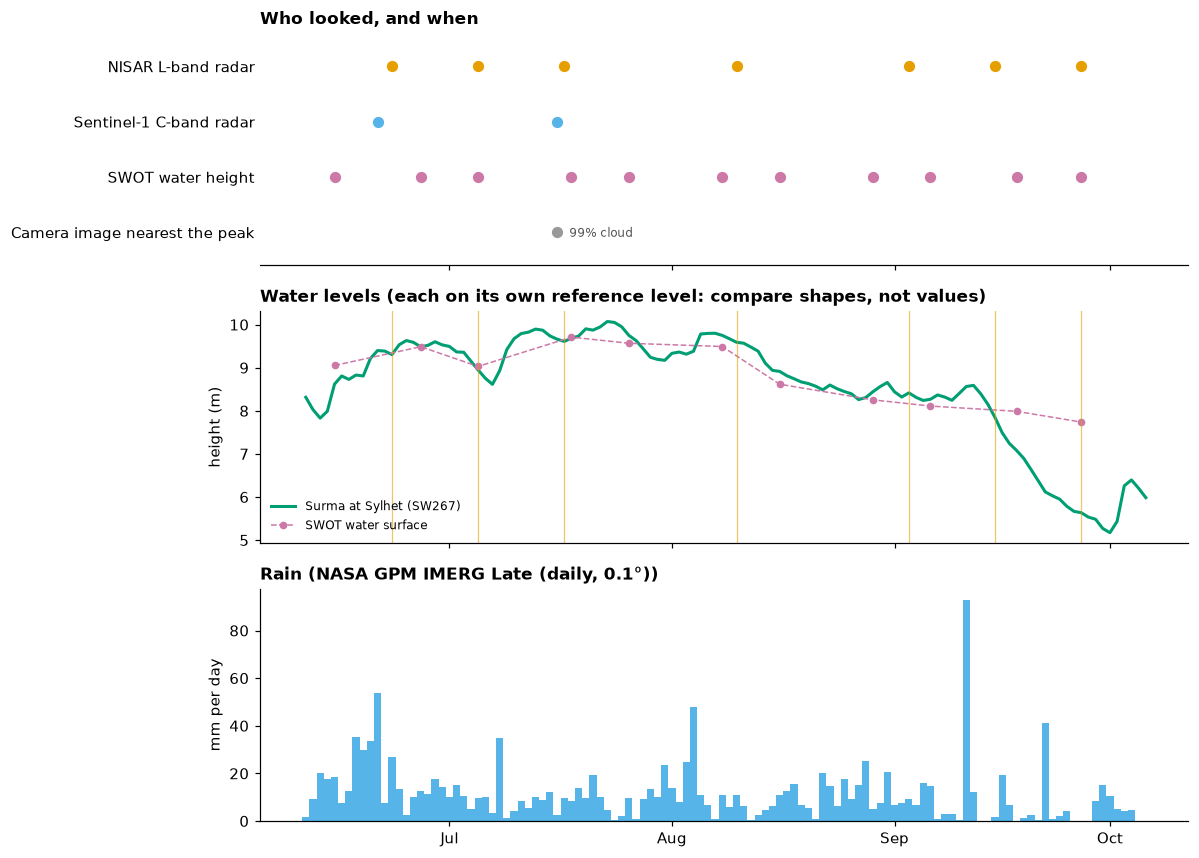

In [4]:
rows = [("NISAR L-band radar", [p["date"] for p in passes], C["lband"]), ("Sentinel-1 C-band radar", [p["cband_date"] for p in passes if p.get("cband_date")], C["cband"]), ("SWOT water height", [r["date"] for r in summary["validation"]["swot"][0]["series"]], C["swot"]), ("Camera image nearest the peak", [opt["date"]], C["built"])]
n = 3
fig, axs = plt.subplots(n, 1, figsize=(11, 2.2 + 1.9 * n), sharex=True, squeeze=False)
axs = axs[:, 0]
a1 = axs[0]
for y, (name, dates, col) in enumerate(rows[::-1]):
    a1.scatter([day(d) for d in dates], [y] * len(dates), s=70, color=col, edgecolor="white", zorder=3)
a1.set_yticks(range(len(rows)), [r[0] for r in rows[::-1]]); a1.tick_params(axis="y", length=0)
a1.spines["left"].set_visible(False); a1.set_ylim(-0.6, len(rows) - 0.4); a1.set_title("Who looked, and when")
for y, (name, dates, col) in enumerate(rows[::-1]):
    if not dates:
        a1.text(day(passes[len(passes) // 2]["date"]), y, "none this season", ha="center", va="center", fontsize=8, color="#888")
if opt.get("date"):
    a1.annotate(f"{opt['cloud_fraction']:.0%} cloud", (day(opt["date"]), 0), xytext=(8, -3), textcoords="offset points", fontsize=8, color="#555")
k = 1

a2 = axs[k]; k += 1
g = summary["validation"].get("gauge")
if g and g.get("stage_daily"):
    a2.plot([day(d) for d, _ in g["stage_daily"]], [v for _, v in g["stage_daily"]], color=C["gauge"], lw=2, label=g["name"])
sw = (summary["validation"].get("swot") or [{}])[0].get("series") or []
if sw:
    a2.plot([day(r["date"]) for r in sw], [r["wse_m"] for r in sw], "o--", color=C["swot"], ms=4, lw=1, label="SWOT water surface")
for p_ in passes:
    a2.axvline(day(p_["date"]), color=C["lband"], lw=0.8, alpha=0.6)
a2.set_ylabel("height (m)"); a2.legend(loc="best", fontsize=8)
a2.set_title("Water levels (each on its own reference level: compare shapes, not values)")

a3 = axs[k]
rain = summary["context"]["rain_daily"]
a3.bar([day(d) for d, _ in rain], [v for _, v in rain], width=1, color=C["rain"])
a3.set_ylabel("mm per day"); a3.set_title(f"Rain ({summary['context'].get('rain_source', 'NASA GPM IMERG')})")

months(axs[-1]); plt.tight_layout(); plt.show()

**Reading the calendar.** NISAR passes every 12 days on the same track, at the same time of day, whatever the
weather (a pass is dropped only if its calibration is off). Count how often each of the other witnesses looked,
and notice how rarely a C-band water map or a clear camera image lines up with a NISAR pass.

> **Pause and think.** If you could only use the camera images, how many dates in this season could you map?

## 2 · How radar sees through the forest

A radar satellite sends a pulse of microwaves sideways and down, and records the **echo**, called
*backscatter* and measured in **decibels (dB)**, a logarithmic scale: +3 dB is about twice the echo, +10 dB ten
times, −10 dB a tenth. What comes back depends on what the pulse meets:

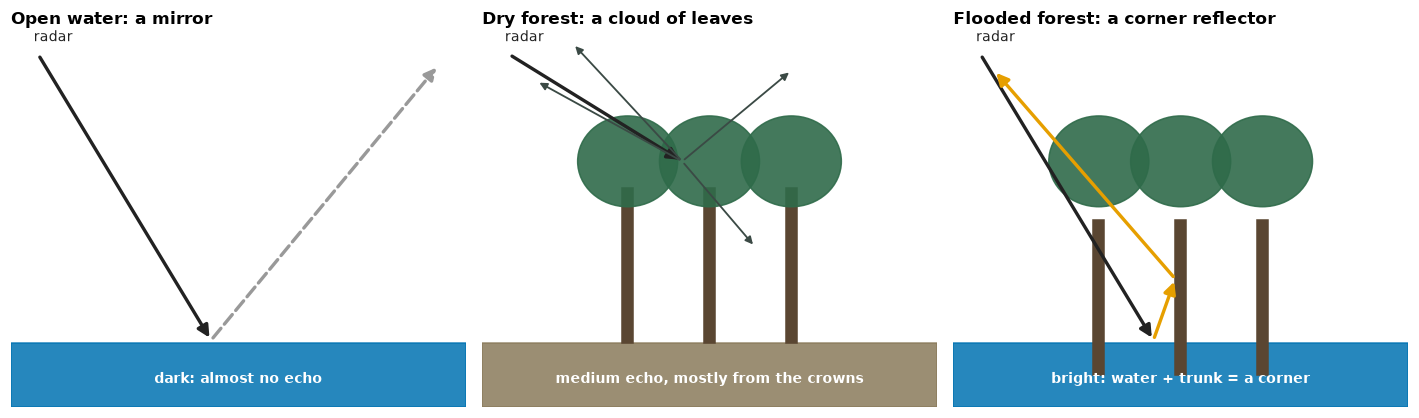

In [5]:
def scene(ax, title, kind):
    ax.set_xlim(0, 10); ax.set_ylim(0, 7); ax.axis("off"); ax.set_title(title)
    ax.add_patch(mpatches.Rectangle((0, 0), 10, 1.2, color=C["water"] if kind != "dry" else C["rock"], alpha=0.85))
    if kind != "open":
        for x in (3.2, 5.0, 6.8):
            ax.add_patch(mpatches.Rectangle((x - 0.12, 0.6 if kind == "flooded" else 1.2), 0.24, 2.9, color="#5a4632"))
            ax.add_patch(mpatches.Ellipse((x, 4.6), 2.2, 1.7, color="#2f6b4a", alpha=0.9))
    arrow = dict(arrowstyle="-|>", lw=2.2, mutation_scale=16)
    ax.annotate("", xy=(4.4, 1.25) if kind != "dry" else (4.4, 4.6), xytext=(0.6, 6.6), arrowprops=dict(color=C["ink"], **arrow))
    if kind == "open":
        ax.annotate("", xy=(9.4, 6.4), xytext=(4.4, 1.25), arrowprops=dict(color="#999", ls="--", **arrow))
        note = "dark: almost no echo"
    elif kind == "dry":
        for dx, dy in [(-3.2, 1.5), (-2.4, 2.2), (2.4, 1.7), (-1.0, 2.5), (1.6, -1.6)]:
            ax.annotate("", xy=(4.4 + dx, 4.6 + dy), xytext=(4.4, 4.6), arrowprops=dict(color=C["dry"], lw=1.2, arrowstyle="-|>"))
        note = "medium echo, mostly from the crowns"
    else:
        ax.annotate("", xy=(4.88, 2.4), xytext=(4.4, 1.25), arrowprops=dict(color=C["hidden"], **arrow))
        ax.annotate("", xy=(0.9, 6.3), xytext=(4.88, 2.4), arrowprops=dict(color=C["hidden"], **arrow))
        note = "bright: water + trunk = a corner"
    ax.text(5, 0.45, note, ha="center", color="white", fontsize=9, weight="bold")
    ax.text(0.5, 6.85, "radar", fontsize=9, color=C["ink"])


fig, axs = plt.subplots(1, 3, figsize=(13, 3.9))
scene(axs[0], "Open water: a mirror", "open")
scene(axs[1], "Dry forest: a cloud of leaves", "dry")
scene(axs[2], "Flooded forest: a corner reflector", "flooded")
plt.tight_layout(); plt.show()

**The double bounce.** In a flooded forest the pulse glances off the flat water like a mirror, strikes a trunk
standing straight up, and comes straight back: water and trunk make a **corner reflector**. Hess, Melack and
Simonett (1990) reviewed the evidence: flooding raises L-band backscatter under forests by roughly **3 to 10 dB**.

**Two polarisations.** NISAR sends its pulse horizontally polarised (H) and listens twice. **HH** (horizontal
back) keeps the double bounce, so it gets **bright**; **HV** (vertical back) comes mostly from messy scattering
in the crowns and **barely changes** when water arrives. The signature is *bright HH and a large HH − HV gap*.

**Why the wavelength matters.** A wave mostly ignores things much smaller than itself. C-band (5.6 cm) is the
size of leaves and twigs and scatters in the crown; L-band (24 cm) passes them and reaches trunks and water.

## 3 · What NISAR measured: opening the data

The project turns NASA's NISAR **GCOV** product (provisional release) into a few small files, defined in
`docs/03_ARCHITECTURE.md` §4: `summary.json` (the site, passes, thresholds and checks), `stack.bin` (per-pass
layers, one byte per pixel, ordered *layer → pass → row → column*) and `static.bin` (layers that do not change:
land cover, terrain, canopy, water history). A byte holds 256 steps, and `value = byte × scale + offset`; for
backscatter the step is 0.25 dB, finer than the radar's own noise.

Per-pass layers: hh, hv, hh_spread, cband, level_cm, vv, vh
Fixed layers:    veg, hydroperiod_days, canopy_cover_pct, canopy_height_m, terrain_gate, jrc_occurrence, hand_m, glwd_class
stack.bin = 7 layers × 7 passes × 247 rows × 256 columns = 3,098,368 bytes


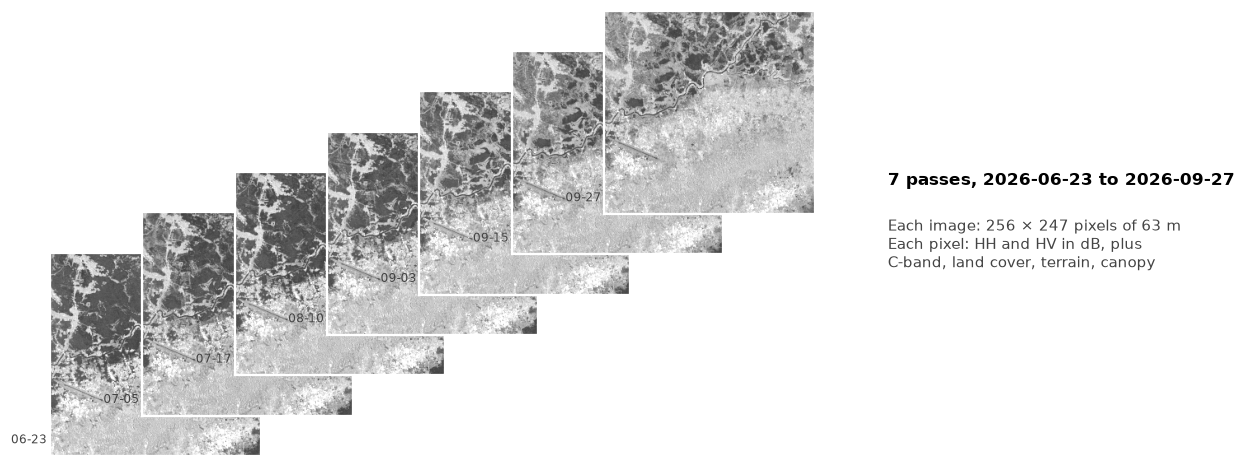

In [6]:
gs = summary["grid_stack"]
W, H, P = grid["width"], grid["height"], len(passes)
stack = np.fromfile(DATA / SITE / gs["stack_file"], np.uint8).reshape(len(gs["layers"]), P, H, W)
static = np.fromfile(DATA / SITE / gs["static_file"], np.uint8).reshape(len(gs["static_layers"]), H, W)
LAYER = {l["name"]: i for i, l in enumerate(gs["layers"])}
STATIC = {l["name"]: i for i, l in enumerate(gs["static_layers"])}


def decode(layer, q):
    """Bytes to values; the layer's no-data byte becomes NaN."""
    out = q.astype(float) * layer.get("scale", 1) + layer.get("offset", 0)
    if layer.get("nodata") is not None:
        out[q == layer["nodata"]] = np.nan
    return out


layer = lambda name: decode(gs["layers"][LAYER[name]], stack[LAYER[name]])
fixed = lambda name: decode(gs["static_layers"][STATIC[name]], static[STATIC[name]])
hh_db, hv_db, spread_db = layer("hh"), layer("hv"), layer("hh_spread")
vv_db, vh_db = layer("vv"), layer("vh")       # Sentinel-1 C-band (OPERA RTC-S1), where matched
cband = stack[LAYER["cband"]]                   # OPERA DSWx-S1: 0 no data, 1 not water, 2 water
veg = static[STATIC["veg"]]                     # ESA WorldCover: 0 other, 1 vegetation, 2 built-up
hydroperiod, hand, jrc = fixed("hydroperiod_days"), fixed("hand_m"), fixed("jrc_occurrence")

print("Per-pass layers:", ", ".join(l["name"] for l in gs["layers"]))
print("Fixed layers:   ", ", ".join(l["name"] for l in gs["static_layers"]))
print(f"stack.bin = {stack.shape[0]} layers × {P} passes × {H} rows × {W} columns = {stack.size:,} bytes")
no_radar = np.isnan(hh_db).all(0).mean()
if no_radar > 0.05:
    print(f"{no_radar:.0%} of the box lies outside NISAR's imaged strip on this track (drawn black): those pixels have no radar at all.")
# D-101: where this track's swath leaves the box empty, each pass is filled from a neighbouring track's
# nearest pass (within 7 days, levels matched over the overlap). The "fill" layer marks those pixels.
for p_ in passes:
    if p_.get("fill"):
        f = p_["fill"]
        print(f"{p_['date']}: {f['share']:.0%} of the box from track {f['track']} {f['direction']} on {f['date']} "
              f"({f['days_apart']:+d} days), level shift HH {f['offset_hh_db']:+.2f} dB, HV {f['offset_hv_db']:+.2f} dB")

fig = plt.figure(figsize=(12, 4.4))
for k, p_ in enumerate(passes):
    ax = fig.add_axes([0.02 + k * (0.42 / max(P - 1, 1)), 0.06 + k * (0.5 / max(P - 1, 1)), 0.25, 0.42])
    ax.imshow(hh_db[k], cmap="gray", vmin=-25, vmax=0)
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_visible(True); sp.set_color("white"); sp.set_linewidth(1.5)
    ax.text(-4, H * 0.92, p_["date"][5:], ha="right", va="center", fontsize=8, color="#444")
fig.text(0.70, 0.62, f"{P} passes, {passes[0]['date']} to {passes[-1]['date']}", fontsize=11, weight="bold")
fig.text(0.70, 0.45, f"Each image: {W} × {H} pixels of {grid['pixel_size_m']:.0f} m\nEach pixel: HH and HV in dB, plus\nC-band, land cover, terrain, canopy", fontsize=10, color="#444")
plt.show()

## 4 · A first look

Radar images are read in grey: bright means a strong echo. Radar scientists also build a **false-colour
composite**, putting three measurements into red, green and blue so different surfaces get different colours.
Here red is HH, green is HV and blue is HH − HV: open water comes out dark blue-violet, vegetation on dry ground
olive-yellow, and the strongest double bounces bright and pinkish (flooded trees, but also buildings, which are
corner reflectors too). The composite shows where to look; deciding is the rule's job (Chapter 5).

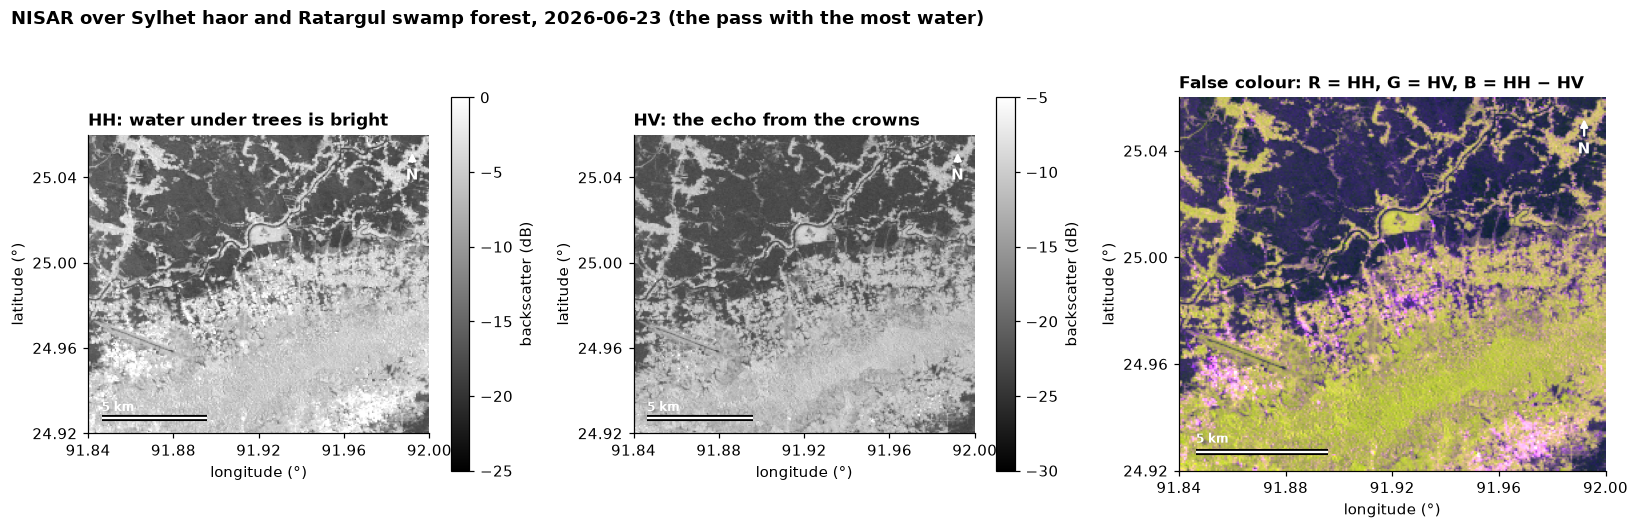

In [7]:
peak = max(range(P), key=lambda k: passes[k]["flooded_km2"])
i = peak
extent = (west, east, south, north)
stretch = lambda x, lo, hi: np.clip((x - lo) / (hi - lo), 0, 1)
rgb = np.nan_to_num(np.dstack([stretch(hh_db[i], -20, 0), stretch(hv_db[i], -26, -6), stretch(hh_db[i] - hv_db[i], 2, 14)]))

fig, axs = plt.subplots(1, 3, figsize=(15, 4.9))
for ax, img, title, kw in [(axs[0], hh_db[i], "HH: water under trees is bright", dict(cmap="gray", vmin=-25, vmax=0)),
                          (axs[1], hv_db[i], "HV: the echo from the crowns", dict(cmap="gray", vmin=-30, vmax=-5))]:
    im = ax.imshow(img, extent=extent, **kw); mapframe(ax, BOUNDS, title)
    fig.colorbar(im, ax=ax, shrink=0.8, label="backscatter (dB)")
axs[2].imshow(rgb, extent=extent); mapframe(axs[2], BOUNDS, "False colour: R = HH, G = HV, B = HH − HV")
plt.suptitle(f"NISAR over {site['name']}, {passes[i]['date']} (the pass with the most water)", x=0.01, ha="left", weight="bold")
plt.tight_layout(); plt.show()

### Three pixels through the season

Maps show one moment. To see the season, follow single pixels. The next cell applies the project's rule
(explained in Chapter 5) and picks, for each kind of surface, the **typical** pixel: of the pixels that stayed
in that class all season, the one whose average echo is closest to the class's median. Typical, not extreme,
because extremes teach the wrong lesson.

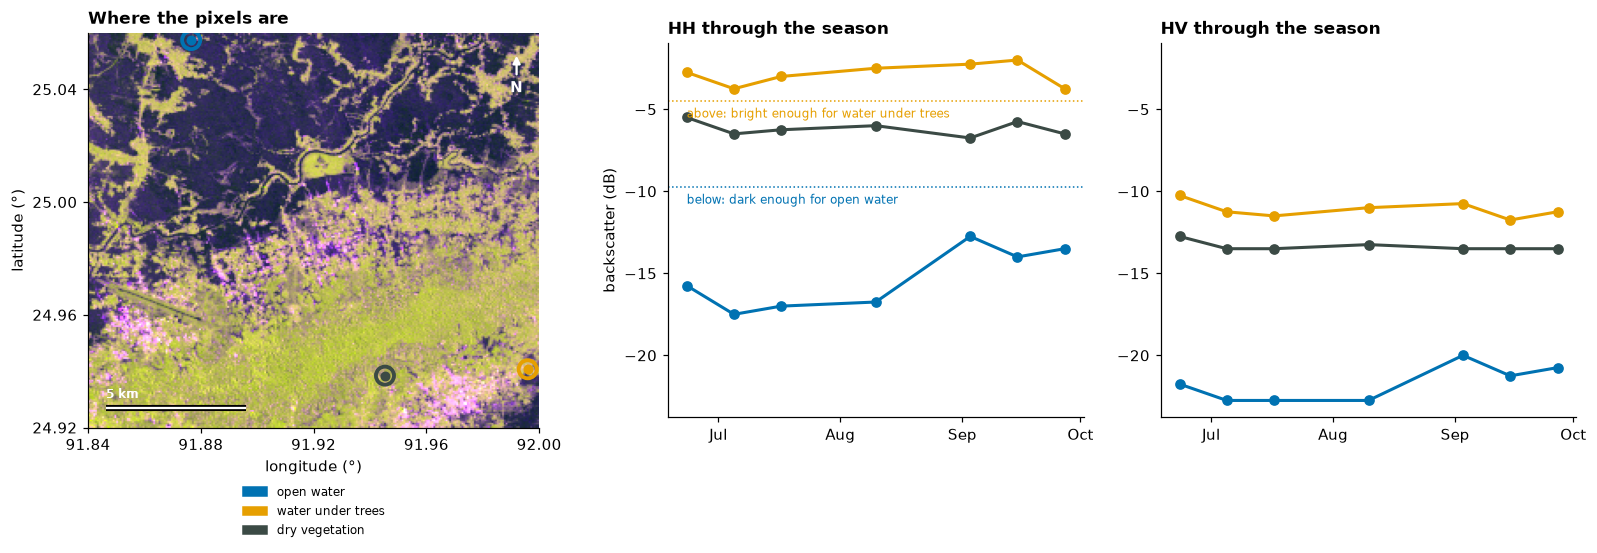

In [8]:
T = summary["thresholds"]
NODATA, DRY, OPEN_WATER, FLOODED_VEG, EXCLUDED = 0, 1, 2, 3, 4   # pipeline/canopy/config.py
VEG_YES, VEG_BUILT_UP = 1, 2


def classify(hh, hv, spread, veg, t):
    """Class and confidence (1 high, 0 low) per pixel: a line-by-line copy of pipeline/canopy/classify.py."""
    hh, hv, spread, veg = np.broadcast_arrays(hh, hv, spread, veg)
    valid = np.isfinite(hh) & np.isfinite(hv)
    hh = np.where(valid, hh, 0.0); hv = np.where(valid, hv, 0.0)
    spread = np.nan_to_num(spread, nan=0.0)
    ratio = hh - hv
    m = t["margin_db"]
    open_water = valid & (hh < t["ow_hh_db"]) & (hv < t["ow_hv_db"])
    excluded = valid & ~open_water & (veg == VEG_BUILT_UP)
    flooded = valid & ~open_water & ~excluded & (veg == VEG_YES) & (hh > t["fv_hh_db"]) & (ratio > t["fv_ratio_db"])
    cls = np.full(hh.shape, NODATA, np.uint8)
    cls[valid] = DRY; cls[open_water] = OPEN_WATER; cls[excluded] = EXCLUDED; cls[flooded] = FLOODED_VEG
    dry = cls == DRY
    low = (valid & ~excluded) & (spread > t["max_spread_db"])
    low |= open_water & (np.minimum(t["ow_hh_db"] - hh, t["ow_hv_db"] - hv) < m)
    low |= flooded & (np.minimum(hh - t["fv_hh_db"], ratio - t["fv_ratio_db"]) < m)
    near_ow = (hh < t["ow_hh_db"] + m) & (hv < t["ow_hv_db"] + m)
    near_fv = (veg == VEG_YES) & (hh > t["fv_hh_db"] - m) & (ratio > t["fv_ratio_db"] - m)
    low |= dry & (near_ow | near_fv)
    return cls, np.where(low, 0, 1).astype(np.uint8)


cls, conf = classify(hh_db, hv_db, spread_db, veg, T)
lat_c = north - (np.arange(H) + 0.5) * (north - south) / H
lon_c = west + (np.arange(W) + 0.5) * (east - west) / W
mean_hh, mean_hv = np.nanmean(hh_db, 0), np.nanmean(hv_db, 0)
count = lambda c: (cls == c).sum(0)


def typical(candidates, c):
    """Of the pixels in class c most often (and at least half the passes), the one nearest the class median."""
    n = np.where(candidates, count(c), 0)
    if n.max() < max(1, P // 2):
        return None
    ok = n >= n.max()
    d = np.hypot(mean_hh - np.median(mean_hh[ok]), mean_hv - np.median(mean_hv[ok]))
    return np.unravel_index(np.argmin(np.where(ok, d, np.inf)), d.shape)


pixels = {name: (rc, col) for name, rc, col in [
    ("open water", typical(np.ones((H, W), bool), OPEN_WATER), C["water"]),
    ("water under trees", typical(veg == VEG_YES, FLOODED_VEG), C["hidden"]),
    ("dry vegetation", typical(veg == VEG_YES, DRY), C["dry"]),
] if rc is not None}

dates = [day(p_["date"]) for p_ in passes]
fig = plt.figure(figsize=(14, 4.6))
ax0 = fig.add_axes([0.02, 0.12, 0.3, 0.78]); ax0.imshow(rgb, extent=extent); mapframe(ax0, BOUNDS, "Where the pixels are")
ax1 = fig.add_axes([0.40, 0.14, 0.27, 0.74]); ax2 = fig.add_axes([0.72, 0.14, 0.27, 0.74], sharey=ax1)
for name, ((r, c), col) in pixels.items():
    ax0.scatter(lon_c[c], lat_c[r], s=140, facecolor="none", edgecolor=col, lw=2.5); ax0.scatter(lon_c[c], lat_c[r], s=30, color=col)
    ax1.plot(dates, hh_db[:, r, c], "o-", color=col, lw=2, label=name)
    ax2.plot(dates, hv_db[:, r, c], "o-", color=col, lw=2)
ax1.axhline(T["fv_hh_db"], color=C["hidden"], ls=":", lw=1); ax1.text(dates[0], T["fv_hh_db"] - 0.4, "above: bright enough for water under trees", va="top", fontsize=8, color=C["hidden"])
ax1.axhline(T["ow_hh_db"], color=C["water"], ls=":", lw=1); ax1.text(dates[0], T["ow_hh_db"] - 0.4, "below: dark enough for open water", va="top", fontsize=8, color=C["water"])
ax1.set_title("HH through the season"); ax2.set_title("HV through the season"); ax1.set_ylabel("backscatter (dB)")
ax0.legend(handles=[mpatches.Patch(color=col, label=n) for n, (_, col) in pixels.items()], loc="upper center", bbox_to_anchor=(0.5, -0.12), fontsize=8)
for ax in (ax1, ax2):
    months(ax)
plt.show()
missing = {"open water", "water under trees", "dry vegetation"} - set(pixels)
if missing:
    print("No pixel stayed in these classes for most of the season here:", ", ".join(sorted(missing)))

**Reading the lines.** Open water sits at the bottom in both channels; dry vegetation in the middle. Where
there is water under trees, its HH sits above the dry vegetation's, while in HV the two are closer: the gap
HH − HV gives it away.

## 5 · From echoes to a map: the decision space

The project uses a short, explicit rule, in the tradition of the L-band wetland maps of the Amazon (Hess et
al. 2003; Hess et al. 2015; Rosenqvist et al. 2020) and the methods reviewed by Tsyganskaya et al. (2018):

1. **Open water**: HH *and* HV both darker than their thresholds (the mirror).
2. **Built-up land** is set aside: buildings are corner reflectors too, so no flood claim is made there.
3. **Water under trees**: on vegetated land, HH brighter than a threshold *and* HH − HV larger than another.
4. Everything else is **dry**.

Each pixel also gets a **confidence**: low within 1 dB of a threshold, or where HH wobbles a lot between
neighbours (speckle, the grain in every radar image). These thresholds were **calibrated for this site** against independent labels (decision D-045 in `docs/10_DECISIONS_AND_RISKS.md`).

The best way to understand a rule is to *see* it: plot every pixel by its two measurements and draw the
thresholds as lines. This picture is the **decision space**.

This site's thresholds (dB): {"ow_hh_db": -9.75, "ow_hv_db": -16.5, "fv_hh_db": -4.5, "fv_ratio_db": 4.25, "margin_db": 1.0, "max_spread_db": 3.0}


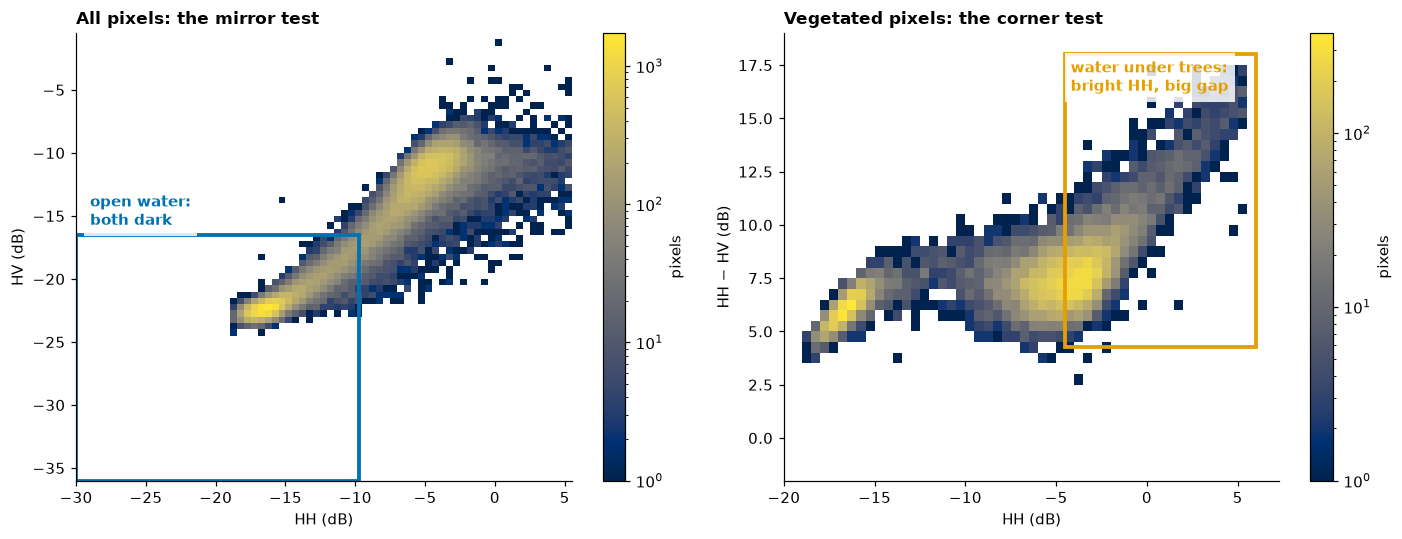

In [9]:
print("This site's thresholds (dB):", json.dumps(T))
sel_all = np.isfinite(hh_db[i]) & np.isfinite(hv_db[i])
sel_veg = sel_all & (veg == VEG_YES)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5))
h1 = a1.hist2d(hh_db[i][sel_all], hv_db[i][sel_all], bins=[np.arange(-30, 6, 0.5), np.arange(-36, 0, 0.5)], cmap="cividis", cmin=1, norm="log")
a1.add_patch(mpatches.Rectangle((-30, -36), T["ow_hh_db"] + 30, T["ow_hv_db"] + 36, fill=False, ec=C["water"], lw=2.5))
a1.text(-29, T["ow_hv_db"] + 0.8, "open water:\nboth dark", color=C["water"], weight="bold", bbox=dict(facecolor="white", edgecolor="none", alpha=0.85))
a1.set_xlabel("HH (dB)"); a1.set_ylabel("HV (dB)"); a1.set_title("All pixels: the mirror test"); fig.colorbar(h1[3], ax=a1, label="pixels")
if sel_veg.sum() > 10:
    h2 = a2.hist2d(hh_db[i][sel_veg], (hh_db[i] - hv_db[i])[sel_veg], bins=[np.arange(-20, 6, 0.5), np.arange(-2, 18, 0.5)], cmap="cividis", cmin=1, norm="log")
    fig.colorbar(h2[3], ax=a2, label="pixels")
a2.add_patch(mpatches.Rectangle((T["fv_hh_db"], T["fv_ratio_db"]), 6 - T["fv_hh_db"], 18 - T["fv_ratio_db"], fill=False, ec=C["hidden"], lw=2.5))
a2.text(T["fv_hh_db"] + 0.3, 16.3, "water under trees:\nbright HH, big gap", color=C["hidden"], weight="bold", bbox=dict(facecolor="white", edgecolor="none", alpha=0.85))
a2.set_xlabel("HH (dB)"); a2.set_ylabel("HH − HV (dB)"); a2.set_title("Vegetated pixels: the corner test")
plt.tight_layout(); plt.show()

The colour counts pixels per small square (log scale, so rare combinations still show); the boxes are the rule.
Look for whether the corner-test box catches a separate cluster or just the bright tail of one cloud: if
there is no clean gap, where you put the line matters, and Chapter 9 measures by how much.

### The map, checked against the app

Now apply the rule to every pass and add up the areas. Pixels on a latitude–longitude grid shrink toward the
poles, so each row has its own area. The `assert` stops the notebook if any number differs from the app's
published summary: this is how you know the notebook and the app do *exactly* the same thing.

pass  date         under trees  open water  hidden from C-band   (km², each equal to the app)
p01   2026-06-23        26.389     100.381              10.958
p02   2026-07-05        21.101      95.404                   -
p03   2026-07-17        24.312     100.922               9.442
p04   2026-08-10        25.581      94.155                   -
p05   2026-09-03        26.341      77.900                   -
p06   2026-09-15        22.828      72.115                   -
p07   2026-09-27        21.145      62.961                   -
Identical to pipeline/canopy/classify.py on all 442,624 pixel-passes.


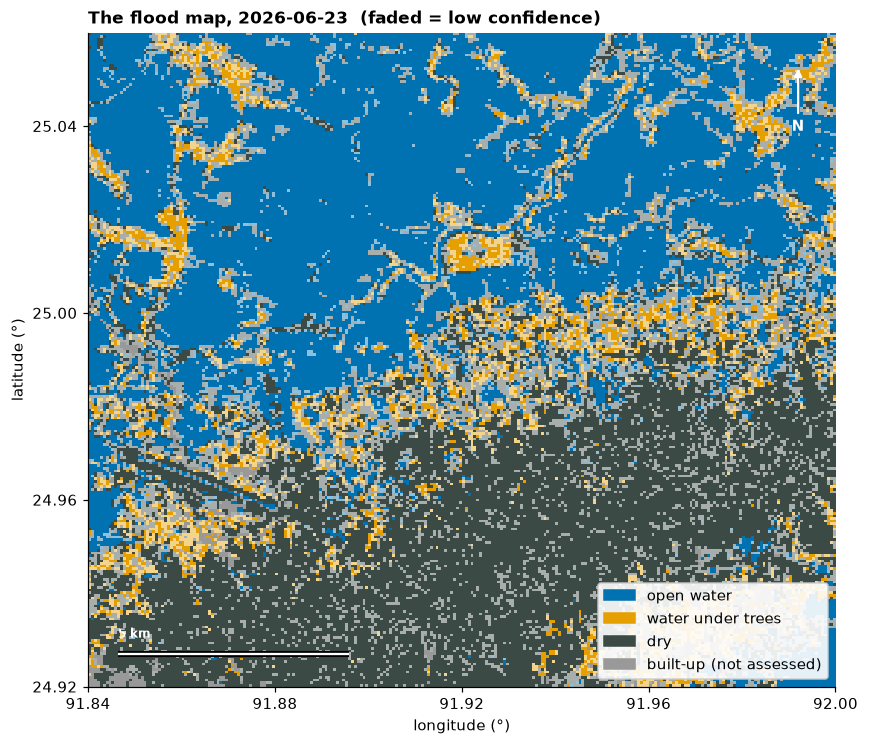

In [10]:
EARTH_M_PER_DEG = 111_320.0   # pipeline/canopy/raster.py
row_km2 = ((east - west) / W * EARTH_M_PER_DEG * np.cos(np.radians(lat_c)) * (north - south) / H * EARTH_M_PER_DEG / 1e6)[:, None]
area = lambda mask: round(float((row_km2 * mask).sum()), 3)
hidden_mask = (cls == FLOODED_VEG) & (conf == 1) & (cband == 1)
print(f"{'pass':5} {'date':11} {'under trees':>12} {'open water':>11} {'hidden from C-band':>19}   (km², each equal to the app)")
for k, p_ in enumerate(passes):
    fv, ow = area(cls[k] == FLOODED_VEG), area(cls[k] == OPEN_WATER)
    hid = area(hidden_mask[k]) if p_.get("hidden_from_cband_km2") is not None else None
    assert (fv, ow, hid) == (p_["flooded_veg_km2"], p_["open_water_km2"], p_.get("hidden_from_cband_km2")), p_["id"]
    print(f"{p_['id']:5} {p_['date']:11} {fv:12.3f} {ow:11.3f} {('-' if hid is None else f'{hid:.3f}'):>19}")
try:
    import sys
    sys.path.insert(0, str(ROOT / "pipeline"))
    from canopy.classify import classify as pipeline_classify
    from canopy.config import Thresholds
    ref = pipeline_classify(hh_db, hv_db, spread_db, veg, Thresholds(**T))
    assert np.array_equal(cls, ref[0]) and np.array_equal(conf, ref[1])
    print(f"Identical to pipeline/canopy/classify.py on all {cls.size:,} pixel-passes.")
except ImportError:
    print("(pipeline/ is not here; the copy above stands on its own, and the areas match the app.)")

CLS_CMAP = ListedColormap([C["nodata"], C["dry"], C["water"], C["hidden"], C["built"]])
CLS_NORM = BoundaryNorm(np.arange(-0.5, 5.5), 5)
legend = lambda ax, **kw: ax.legend(handles=[mpatches.Patch(color=C[k], label=l) for k, l in
                                            [("water", "open water"), ("hidden", "water under trees"), ("dry", "dry"), ("built", "built-up (not assessed)")]], **kw)
fig, ax = plt.subplots(figsize=(8, 7.4))
ax.imshow(cls[i], extent=extent, cmap=CLS_CMAP, norm=CLS_NORM, interpolation="nearest", alpha=0.45)
ax.imshow(np.where((conf[i] == 0) & (cls[i] != EXCLUDED), np.nan, cls[i]).astype(float), extent=extent, cmap=CLS_CMAP, norm=CLS_NORM, interpolation="nearest")
mapframe(ax, BOUNDS, f"The flood map, {passes[i]['date']}  (faded = low confidence)")
legend(ax, loc="lower right", facecolor="white", framealpha=0.9, frameon=True)
plt.tight_layout(); plt.show()

## 6 · L-band against C-band: measuring the difference

The heart of the project's claim is that L-band sees water under trees that C-band misses. On the passes below,
Sentinel-1 (C-band, VV and VH, from NASA's OPERA RTC-S1) looked within days of NISAR, so the two radars can be
compared over the **same pixels**: those the rule calls water-under-trees (high confidence) against vegetation
it calls dry (high confidence).

Pass 2026-06-23, C-band 2026-06-21: 2,788 flooded and 2,468 dry vegetated pixels with both radars.


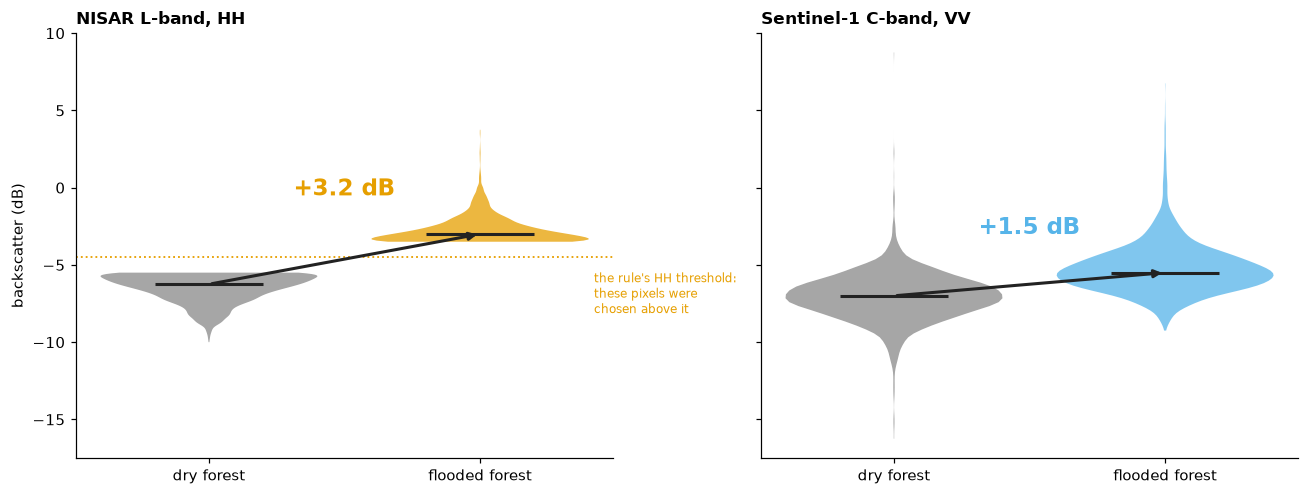

Finding: flooded forest is +3.2 dB brighter than dry forest in L-band HH, +1.5 dB in C-band VV.


In [11]:
cb_passes = [k for k, p_ in enumerate(passes) if p_.get("hidden_from_cband_km2") is not None]
ic = max(cb_passes, key=lambda k: passes[k]["flooded_veg_km2"])
fv_px = (cls[ic] == FLOODED_VEG) & (conf[ic] == 1) & np.isfinite(vv_db[ic])
dry_px = (cls[ic] == DRY) & (veg == VEG_YES) & (conf[ic] == 1) & np.isfinite(vv_db[ic])
if not np.isfinite(vv_db[ic]).any():
    print("Here the C-band water map (OPERA DSWx-S1) exists, but not its backscatter (OPERA RTC-S1), so only the maps are compared below.")
print(f"Pass {passes[ic]['date']}, C-band {passes[ic].get('rtc_date') or passes[ic].get('cband_date')}: "
      f"{fv_px.sum():,} flooded and {dry_px.sum():,} dry vegetated pixels with both radars.")
if fv_px.sum() >= 30 and dry_px.sum() >= 30:
    fig, axs = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
    deltas = {}
    for ax, (name, band, col) in zip(axs, [("NISAR L-band, HH", hh_db[ic], C["lband"]), ("Sentinel-1 C-band, VV", vv_db[ic], C["cband"])]):
        data = [band[dry_px], band[fv_px]]
        parts = ax.violinplot(data, showmedians=True, showextrema=False, widths=0.8)
        for b, fc in zip(parts["bodies"], ["#888", col]):
            b.set_facecolor(fc); b.set_alpha(0.75); b.set_edgecolor("none")
        parts["cmedians"].set_color(C["ink"]); parts["cmedians"].set_linewidth(2)
        med = [np.median(d) for d in data]
        deltas[name] = med[1] - med[0]
        ax.annotate("", xy=(2, med[1]), xytext=(1, med[0]), arrowprops=dict(arrowstyle="-|>", lw=2, color=C["ink"]))
        ax.text(1.5, max(med) + 2.5, f"{med[1] - med[0]:+.1f} dB", ha="center", fontsize=15, weight="bold", color=col)
        ax.set_xticks([1, 2], ["dry forest", "flooded forest"]); ax.set_title(name)
    axs[0].set_ylabel("backscatter (dB)")
    axs[0].axhline(T["fv_hh_db"], color=C["hidden"], ls=":", lw=1.2)
    axs[0].text(2.42, T["fv_hh_db"] - 0.9, "the rule's HH threshold:\nthese pixels were\nchosen above it", fontsize=8, color=C["hidden"], va="top")
    plt.tight_layout(); plt.show()
    lc, cc = deltas["NISAR L-band, HH"], deltas["Sentinel-1 C-band, VV"]
    print(f"Finding: flooded forest is {lc:+.1f} dB brighter than dry forest in L-band HH, {cc:+.1f} dB in C-band VV.")
else:
    print("Too few pixels of each kind with both radars here for a fair comparison; see the agreement map below.")

**Honest caveat.** The pixels were chosen by an L-band rule, so an L-band difference is partly built in (the
dotted line shows the cut). The **C-band** difference is the fairer test: C-band played no part in choosing
the pixels. Hess et al. (1990) found 3–10 dB at L-band; a weak contrast means a sparse or partly flooded forest.

### Where the two radars disagree

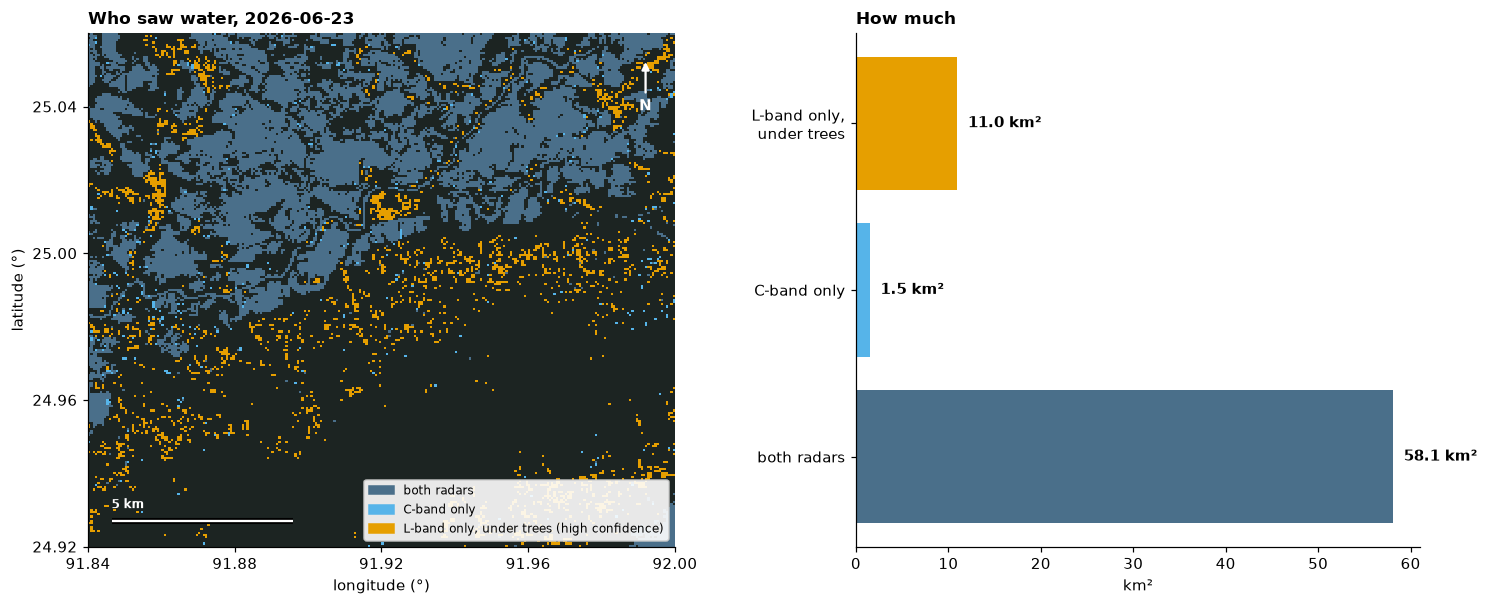

In [12]:
both = (cband[ic] == 2) & np.isin(cls[ic], [OPEN_WATER, FLOODED_VEG])
l_only = (cband[ic] == 1) & (cls[ic] == FLOODED_VEG) & (conf[ic] == 1)
c_only = (cband[ic] == 2) & (cls[ic] == DRY)
agree = np.zeros((H, W)); agree[both] = 1; agree[c_only] = 2; agree[l_only] = 3
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw=dict(width_ratios=[1.3, 1]))
a1.imshow(agree, extent=extent, interpolation="nearest", cmap=ListedColormap(["#1c2422", "#4a6f8a", C["cband"], C["hidden"]]), norm=BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5], 4))
mapframe(a1, BOUNDS, f"Who saw water, {passes[ic]['date']}")
a1.legend(handles=[mpatches.Patch(color="#4a6f8a", label="both radars"), mpatches.Patch(color=C["cband"], label="C-band only"),
                   mpatches.Patch(color=C["hidden"], label="L-band only, under trees (high confidence)")], loc="lower right", facecolor="white", framealpha=0.9, frameon=True, fontsize=8)
vals = [area(both), area(c_only), area(l_only)]
a2.barh(["both radars", "C-band only", "L-band only,\nunder trees"], vals, color=["#4a6f8a", C["cband"], C["hidden"]])
for y, v in enumerate(vals):
    a2.text(v + max(vals) * 0.02, y, f"{v:.1f} km²", va="center", weight="bold")
a2.set_xlabel("km²"); a2.set_title("How much")
assert abs(vals[2] - passes[ic]["hidden_from_cband_km2"]) < 1e-6
plt.tight_layout(); plt.show()

The amber area, **water under trees that C-band called dry**, is the app's headline number for this pass. The
light-blue area is water C-band saw and L-band did not: often wind-roughened or weedy open water that is not
quite a mirror. Neither radar is the truth; the next chapters bring in witnesses that are not radar.

## 7 · Through the season

**Small multiples**: the same map, pass after pass, on the same scale, so the eye can compare without
remembering.

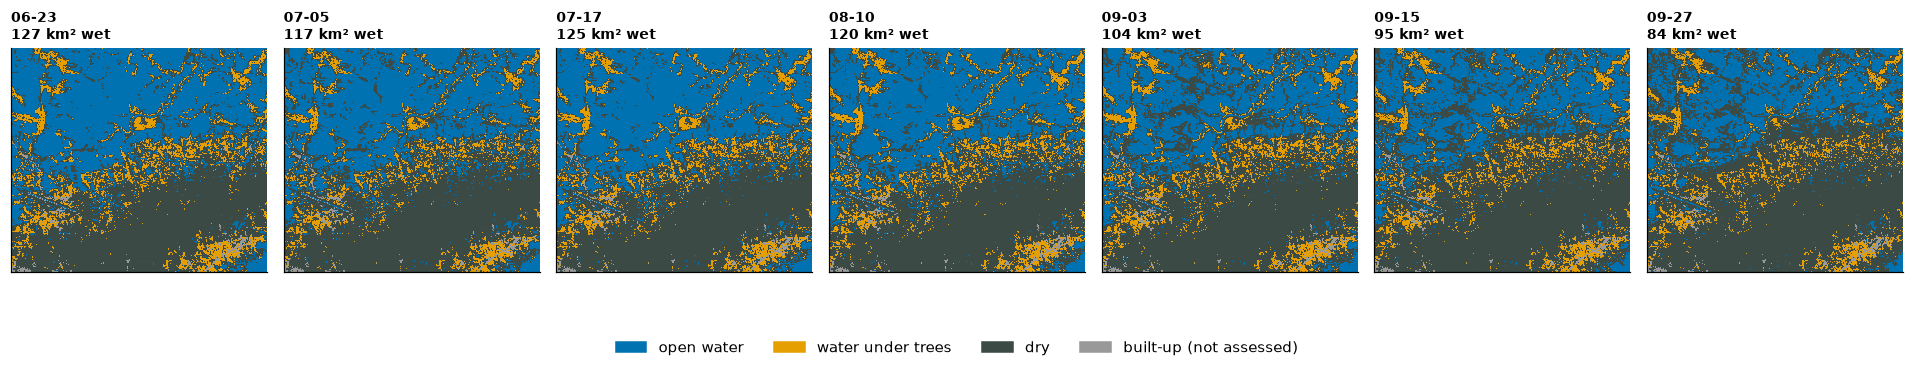

Open water: 63.0–100.9 km² over the season; water under trees: 21.1–26.4 km².


In [13]:
cols = min(P, 8)
fig, axs = plt.subplots(1, cols, figsize=(2.5 * cols, 3.4), squeeze=False)
for k, ax in enumerate(axs[0]):
    ax.imshow(cls[k], extent=extent, cmap=CLS_CMAP, norm=CLS_NORM, interpolation="nearest")
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{passes[k]['date'][5:]}\n{passes[k]['flooded_km2']:.0f} km² wet", fontsize=9)
legend(fig, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.06))
plt.tight_layout(); plt.show()
ow = np.array([p_["open_water_km2"] for p_ in passes]); fv = np.array([p_["flooded_veg_km2"] for p_ in passes])
print(f"Open water: {ow.min():.1f}–{ow.max():.1f} km² over the season; water under trees: {fv.min():.1f}–{fv.max():.1f} km².")

### Does the map follow the river?

A **river gauge** is a witness that knows nothing about radar: a ruler in the water, read every day. If the map
measures water, the mapped area should rise and fall with the river.

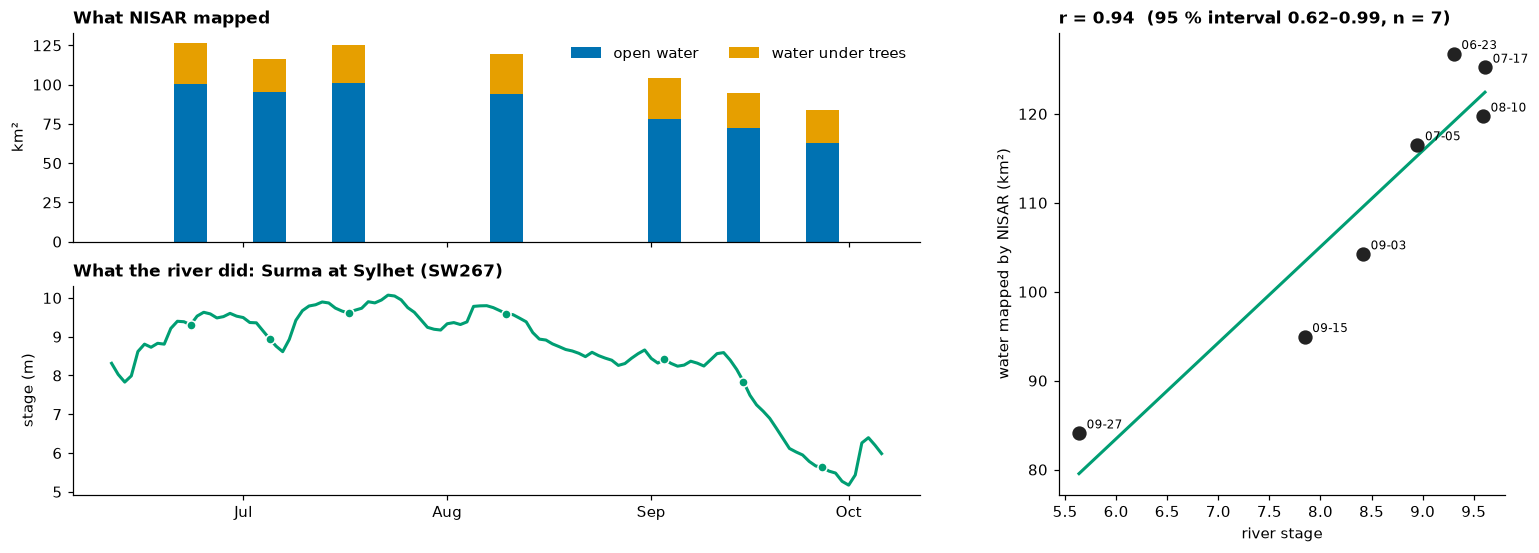

The app reports r = 0.937 (n = 7). Matching each pass with the gauge 3 days later gives r = 0.977.


In [14]:
g = summary["validation"]["gauge"]
# A pass after the gauge's last reading has no stage; the comparison uses the passes that do.
g["series"] = [s_ for s_ in g["series"] if s_["stage_m"] is not None]
x = np.array([s_["stage_m"] for s_ in g["series"]]); y = np.array([s_["flooded_km2"] for s_ in g["series"]])
r, lo, hi = pearson_ci(x, y)
fig = plt.figure(figsize=(14, 5))
a1 = fig.add_axes([0.05, 0.56, 0.55, 0.38]); a2 = fig.add_axes([0.05, 0.1, 0.55, 0.38], sharex=a1); a3 = fig.add_axes([0.69, 0.1, 0.29, 0.84])
a1.bar(dates, ow, width=5, color=C["water"], label="open water"); a1.bar(dates, fv, bottom=ow, width=5, color=C["hidden"], label="water under trees")
a1.set_ylabel("km²"); a1.set_title("What NISAR mapped"); a1.legend(loc="upper right", ncol=2); a1.tick_params(labelbottom=False)
a2.plot([day(d) for d, _ in g["stage_daily"]], [v for _, v in g["stage_daily"]], color=C["gauge"], lw=2)
a2.scatter([day(s_["date"]) for s_ in g["series"]], x, color=C["gauge"], zorder=3, edgecolor="white")
a2.set_ylabel(f"stage ({g.get('units', 'm')})"); a2.set_title(f"What the river did: {g['name']}"); months(a2)
a3.scatter(x, y, s=70, color=C["ink"], zorder=3)
for s_ in g["series"]:
    a3.annotate(s_["date"][5:], (s_["stage_m"], s_["flooded_km2"]), xytext=(5, 3), textcoords="offset points", fontsize=8)
fit = np.polyfit(x, y, 1); xs = np.linspace(x.min(), x.max(), 10); a3.plot(xs, np.polyval(fit, xs), color=C["gauge"], lw=2)
a3.set_xlabel("river stage"); a3.set_ylabel("water mapped by NISAR (km²)")
a3.set_title(f"r = {r:.2f}  (95 % interval {lo:.2f}–{hi:.2f}, n = {len(x)})")
plt.show()
lag = g.get("best_lag_days") or 0
print(f"The app reports r = {g['r']} (n = {g['n']}).", f"Matching each pass with the gauge {abs(lag)} days {'later' if lag < 0 else 'earlier'} gives r = {g['r_best']}." if lag else "")

**Always report the uncertainty of a statistic, not just its value.** With a handful of passes the 95 % interval
is wide, and the title shows it. A best match at a time *lag* tells you which moves first, the floodplain or the
river at the gauge.

## 8 · Where the water lives: terrain and history

* **HAND**, *height above nearest drainage* (Nobre et al. 2011): how far above the nearest stream a pixel sits.
  Water collects low.
* **JRC Global Surface Water occurrence** (Pekel et al. 2016): the share of Landsat images, 1984–2021, in which a
  pixel was water. Water under trees should mostly be *outside* it: cameras cannot see under canopy.
* **Hydroperiod**: how many days of the season the radar saw each pixel wet.

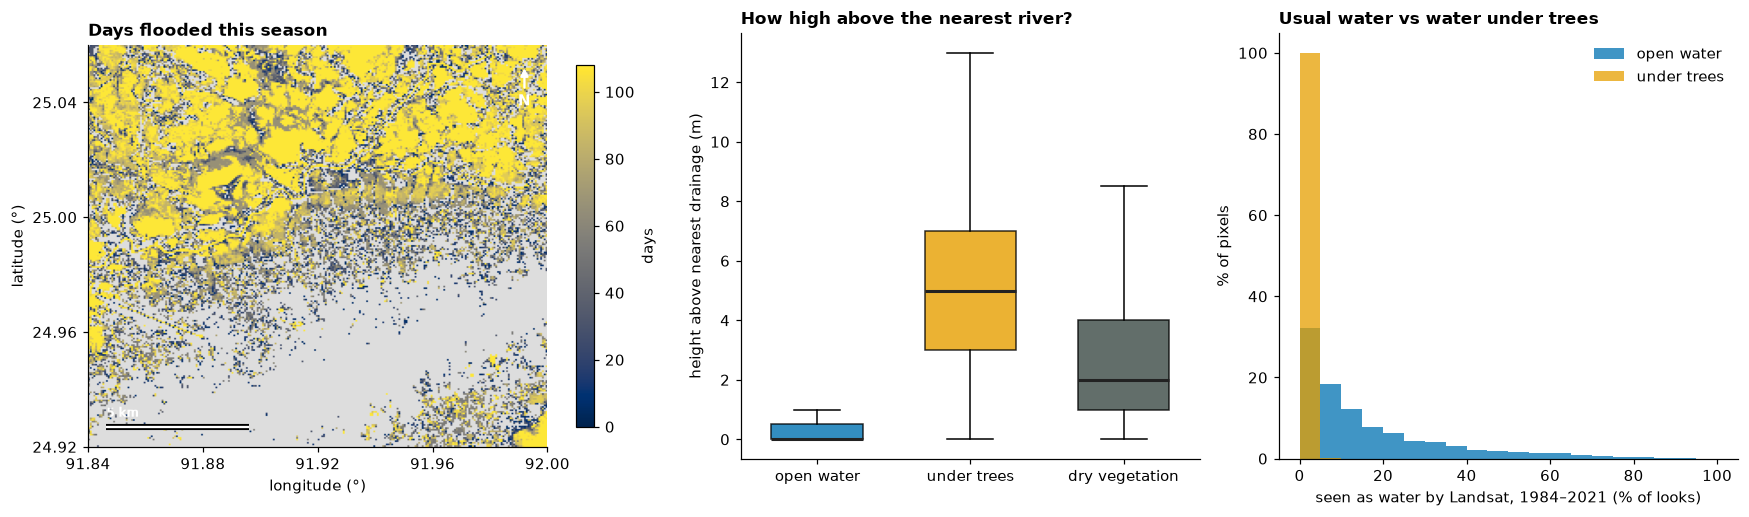

open water      median HAND   0.0 m · median Landsat water   9.0 %
under trees     median HAND   5.0 m · median Landsat water   0.0 %
dry vegetation  median HAND   2.0 m · median Landsat water   0.0 %


In [15]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw=dict(width_ratios=[1.25, 1, 1]))
im = axs[0].imshow(np.where(hydroperiod > 0, hydroperiod, np.nan), extent=extent, cmap="cividis", vmin=0, vmax=max(1, summary["products"]["hydroperiod"].get("season_days") or np.nanmax(hydroperiod)))
axs[0].set_facecolor("#ddd"); mapframe(axs[0], BOUNDS, "Days flooded this season"); fig.colorbar(im, ax=axs[0], shrink=0.85, label="days")
groups = [("open water", (cls[i] == OPEN_WATER) & (conf[i] == 1), C["water"]),
          ("under trees", (cls[i] == FLOODED_VEG) & (conf[i] == 1), C["hidden"]),
          ("dry vegetation", (cls[i] == DRY) & (veg == VEG_YES) & (conf[i] == 1), C["dry"])]
groups = [(n, m & np.isfinite(hand), c) for n, m, c in groups if (m & np.isfinite(hand)).sum() >= 20]
if groups:
    bp = axs[1].boxplot([hand[m] for _, m, _ in groups], patch_artist=True, showfliers=False, widths=0.6, medianprops=dict(color=C["ink"], lw=2))
    for b, (_, _, col) in zip(bp["boxes"], groups):
        b.set_facecolor(col); b.set_alpha(0.8)
    axs[1].set_xticks(range(1, len(groups) + 1), [n for n, _, _ in groups])
axs[1].set_ylabel("height above nearest drainage (m)"); axs[1].set_title("How high above the nearest river?")
for n, m, col in groups:
    v = jrc[m & np.isfinite(jrc)]
    if n != "dry vegetation" and v.size:
        axs[2].hist(v, bins=np.arange(0, 105, 5), color=col, alpha=0.75, label=n, weights=np.full(v.size, 100 / v.size))
axs[2].set_xlabel("seen as water by Landsat, 1984–2021 (% of looks)"); axs[2].set_ylabel("% of pixels"); axs[2].set_title("Usual water vs water under trees"); axs[2].legend()
plt.tight_layout(); plt.show()
for n, m, _ in groups:
    print(f"{n:15} median HAND {np.median(hand[m]):5.1f} m · median Landsat water {np.median(jrc[m & np.isfinite(jrc)]) if (m & np.isfinite(jrc)).any() else float('nan'):5.1f} %")

**What to look for.** Open water should sit on the drainage (HAND near 0 m) and in Landsat's record. Water under
trees should be low-lying but *outside* the Landsat record. If flagged pixels sit **higher** than the dry
vegetation, some may be false positives (bright, structured vegetation not standing in water): independent data
does not just confirm, it points at where to look harder.

## 9 · How sure are we? Sensitivity to the thresholds

A map made with thresholds is only as firm as its thresholds. Shift each water-under-trees threshold by up to
±1 dB (about the radar's calibration uncertainty), rerun the rule, and watch the area move.

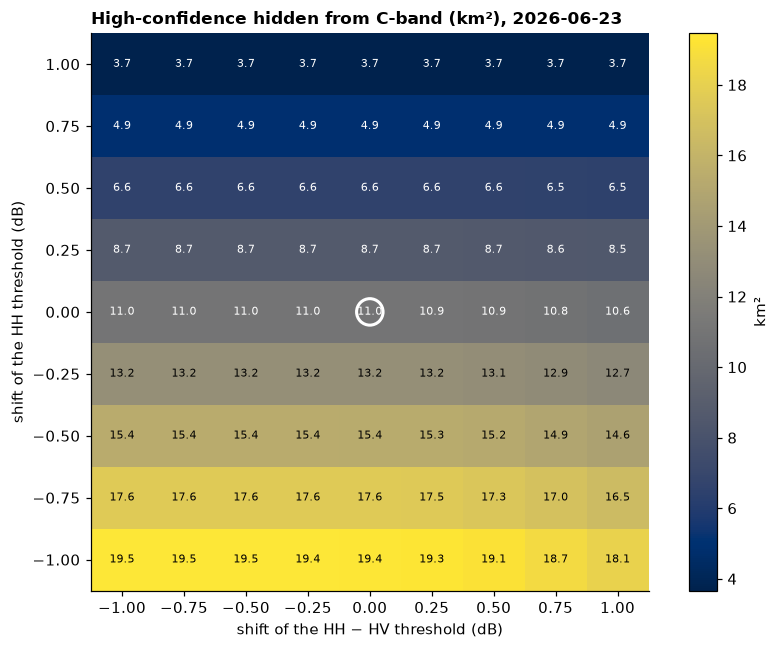

At the thresholds used: 11.0 km². HH threshold 0.5 dB lower: 15.4 km²; 0.5 dB higher: 6.6 km².
HH − HV threshold 0.5 dB lower: 11.0 km²; 0.5 dB higher: 10.9 km².


In [16]:
p_hid = bool([k for k, p_ in enumerate(passes) if p_.get('hidden_from_cband_km2') is not None])
ih = max([k for k, p_ in enumerate(passes) if p_.get('hidden_from_cband_km2') is not None], key=lambda k: passes[k]['flooded_veg_km2']) if p_hid else i
target = "hidden from C-band" if p_hid else "water under trees"
steps = np.arange(-1.0, 1.01, 0.25)
grid_km2 = np.zeros((len(steps), len(steps)))
for a, dh in enumerate(steps):
    for b, dr in enumerate(steps):
        c, k = classify(hh_db[ih], hv_db[ih], spread_db[ih], veg, dict(T, fv_hh_db=T["fv_hh_db"] + dh, fv_ratio_db=T["fv_ratio_db"] + dr))
        m = (c == FLOODED_VEG) & (k == 1) & ((cband[ih] == 1) if p_hid else True)
        grid_km2[a, b] = area(m)
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(grid_km2, origin="lower", cmap="cividis", extent=(steps[0] - 0.125, steps[-1] + 0.125, steps[0] - 0.125, steps[-1] + 0.125))
for a, dh in enumerate(steps):
    for b, dr in enumerate(steps):
        ax.text(dr, dh, f"{grid_km2[a, b]:.1f}" if grid_km2.max() < 20 else f"{grid_km2[a, b]:.0f}", ha="center", va="center", fontsize=7,
                color="white" if grid_km2[a, b] < grid_km2.max() * 0.6 else "black")
ax.scatter([0], [0], s=300, facecolor="none", edgecolor="white", lw=2)
ax.set_xlabel("shift of the HH − HV threshold (dB)"); ax.set_ylabel("shift of the HH threshold (dB)")
ax.set_title(f"High-confidence {target} (km²), {passes[ih]['date']}"); fig.colorbar(im, ax=ax, label="km²")
plt.tight_layout(); plt.show()
base = grid_km2[4, 4]
print(f"At the thresholds used: {base:.1f} km². HH threshold 0.5 dB lower: {grid_km2[2, 4]:.1f} km²; 0.5 dB higher: {grid_km2[6, 4]:.1f} km².")
print(f"HH − HV threshold 0.5 dB lower: {grid_km2[4, 2]:.1f} km²; 0.5 dB higher: {grid_km2[4, 6]:.1f} km².")

**Read the grid row by row and column by column.** If moving one threshold by half a decibel changes the area a
lot, that threshold is the one to study next, with better labels: field plots, drone surveys, or a probability
sample of reference points, the standard of Olofsson et al. (2014) for estimating areas with honest error bars.

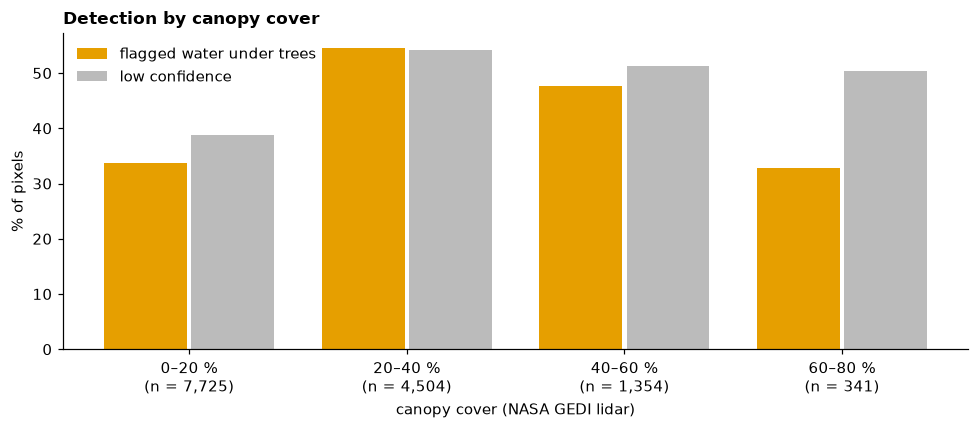

In [17]:
cover = [c for c in summary["products"]["canopy"]["detection_by_cover"] if c["pixels"]]
xc = np.arange(len(cover))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(xc - 0.2, [100 * c["hidden_share"] for c in cover], width=0.38, color=C["hidden"], label="flagged water under trees")
ax.bar(xc + 0.2, [100 * c["low_conf_share"] for c in cover], width=0.38, color="#bbb", label="low confidence")
ax.set_xticks(xc, [f"{c['cover_from']}–{c['cover_to']} %\n(n = {c['pixels']:,})" for c in cover])
ax.set_xlabel("canopy cover (NASA GEDI lidar)"); ax.set_ylabel("% of pixels"); ax.set_title("Detection by canopy cover"); ax.legend()
plt.tight_layout(); plt.show()

Canopy cover from NASA's GEDI lidar (Dubayah et al. 2020) changes how much of the pulse reaches the water: compare how often each cover class is flagged, and how often it is uncertain.

## 10 · Can machine learning do better?

Machine learning learns a rule from labelled examples. For water *under trees* there are no labels at scale (the
gap NISAR is meant to fill). The best independent labels here are **C-band water maps** (OPERA DSWx-S1) on the
matched passes. So the honest question is:

> From NISAR's HH and HV, can a model learn what C-band calls water, and does it then find what C-band cannot see?

Two models: **logistic regression** on three numbers per pixel (HH, HV, HH − HV), and a small **convolutional
network** (CNN) that also sees each pixel's 7 × 7 neighbourhood, the kind of model used on the Sen1Floods11
benchmark (Bonafilia et al. 2020).

**Testing it properly.** Neighbouring pixels are alike, so a model tested on pixels next to its training pixels
can score well by remembering the neighbourhood. Roberts et al. (2017) showed that random splits of such data
overstate accuracy and recommended **spatial block cross-validation**. We do both and compare.

In [18]:
try:
    import torch
    import torch.nn as nn
    HAVE_TORCH = True
except ImportError:
    HAVE_TORCH = False
    print("PyTorch is not installed here (Colab has it): the CNN is skipped, logistic regression runs.")
from sklearn.linear_model import LogisticRegression

labelled = [k for k, p_ in enumerate(passes) if p_.get("hidden_from_cband_km2") is not None]
# At most three labelled passes (those with the most C-band water): enough to teach the method, and
# the chapter then runs in about a minute on a laptop or a free Colab machine.
labelled = sorted(sorted(labelled, key=lambda k: -(cband[k] == 2).sum())[:3])
X = np.stack([np.nan_to_num(np.stack([(hh_db[k] + 30) / 30, (hv_db[k] + 35) / 30, (hh_db[k] - hv_db[k]) / 15]), nan=0.0) for k in labelled]).astype(np.float32)
Y = np.stack([cband[k] for k in labelled]).astype(np.int64) - 1
Y[~np.stack([np.isfinite(hh_db[k]) & np.isfinite(hv_db[k]) for k in labelled])] = -1
rng = np.random.default_rng(0)
BLOCK, K = 32, 5
block_id = (np.arange(H)[:, None] // BLOCK) * 1000 + np.arange(W)[None, :] // BLOCK
blocks = np.unique(block_id)
fold_block = dict(zip(blocks, rng.permutation(len(blocks)) % K))
FOLDS = {"random pixels": rng.integers(0, K, (H, W)), "spatial blocks": np.vectorize(fold_block.get)(block_id)}
n_water, n_dry = int((Y == 1).sum()), int((Y == 0).sum())
print("Passes with C-band labels:", [passes[k]["id"] for k in labelled], f"| labelled pixels: {n_water:,} water, {n_dry:,} not water")
ML_OK = n_water >= 200 and n_dry >= 200
if not ML_OK:
    print("Too few pixels of one class for a fair test here; the models are skipped.")

Passes with C-band labels: ['p01', 'p03'] | labelled pixels: 27,958 water, 98,506 not water


In [19]:
def train_cnn(xt, yt, seed, epochs=200):
    torch.manual_seed(seed)
    net = nn.Sequential(nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.Conv2d(16, 16, 3, padding=1), nn.ReLU(), nn.Conv2d(16, 2, 3, padding=1))
    opt = torch.optim.Adam(net.parameters(), lr=0.01)
    for _ in range(epochs):
        opt.zero_grad(); nn.functional.cross_entropy(net(xt), yt, ignore_index=-1).backward(); opt.step()
    return net


def cross_validate(fold):
    """Each fold is predicted by models that never saw its labels."""
    pred = {"logistic regression": np.zeros(Y.shape, int)}
    if HAVE_TORCH:
        pred["CNN"] = np.zeros(Y.shape, int)
    feats = np.moveaxis(X, 1, -1)
    for f in range(K):
        test = np.broadcast_to(fold == f, Y.shape)
        train = (Y >= 0) & ~test
        if len(np.unique(Y[train])) < 2:
            continue
        pred["logistic regression"][test] = LogisticRegression(max_iter=500).fit(feats[train], Y[train]).predict(feats[test])
        if HAVE_TORCH:
            net = train_cnn(torch.from_numpy(X), torch.from_numpy(np.where(test, -1, Y)), seed=f)
            with torch.no_grad():
                pred["CNN"][test] = net(torch.from_numpy(X)).argmax(1).numpy()[test]
    return pred


def scores(called, truth):
    tp, fp, fn = (called & truth).sum(), (called & ~truth).sum(), (~called & truth).sum()
    p_, r_ = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    return dict(precision=p_, recall=r_, F1=2 * p_ * r_ / max(p_ + r_, 1e-9), IoU=tp / max(tp + fp + fn, 1))


if ML_OK:
    valid, truth = Y >= 0, Y == 1
    rule = np.stack([cls[k] for k in labelled])
    results, preds = {}, {}
    for split, fold in FOLDS.items():
        preds[split] = cross_validate(fold)
        for model, pr in preds[split].items():
            results[(model, split)] = scores((pr == 1)[valid], truth[valid])
    results[("rule: open water", "no training")] = scores((rule == OPEN_WATER)[valid], truth[valid])
    results[("rule: open water + under trees", "no training")] = scores(np.isin(rule, [OPEN_WATER, FLOODED_VEG])[valid], truth[valid])
    print(f"{'model':32} {'tested on':16} precision  recall    F1    IoU   (agreement with C-band water)")
    for (model, split), s_ in results.items():
        print(f"{model:32} {split:16} " + "  ".join(f"{s_[k]:6.3f}" for k in ("precision", "recall", "F1", "IoU")))

model                            tested on        precision  recall    F1    IoU   (agreement with C-band water)
logistic regression              random pixels     0.704   0.851   0.770   0.626
CNN                              random pixels     0.712   0.786   0.747   0.596
logistic regression              spatial blocks    0.696   0.847   0.764   0.618
CNN                              spatial blocks    0.699   0.786   0.740   0.587
rule: open water                 no training       0.532   0.962   0.685   0.521
rule: open water + under trees   no training       0.428   0.969   0.593   0.422


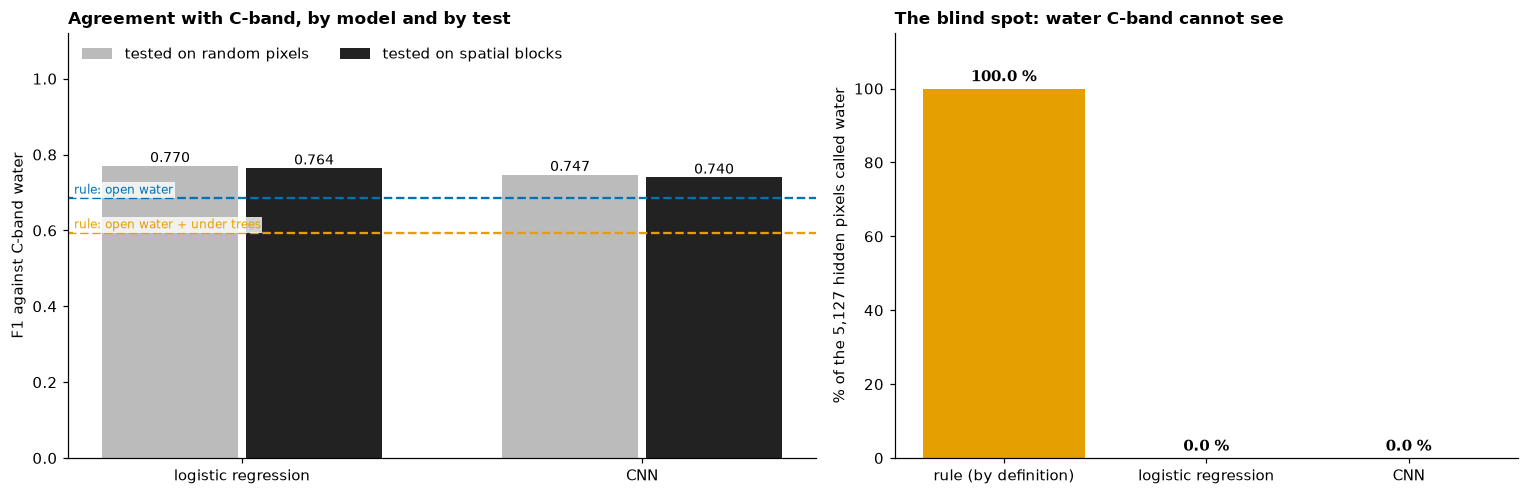

In [20]:
if ML_OK:
    names = [n for n in ("logistic regression", "CNN") if (n, "spatial blocks") in results]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw=dict(width_ratios=[1.2, 1]))
    xb = np.arange(len(names))
    for off, split, col in [(-0.18, "random pixels", "#bbb"), (0.18, "spatial blocks", C["ink"])]:
        vals = [results[(n, split)]["F1"] for n in names]
        a1.bar(xb + off, vals, width=0.34, color=col, label=f"tested on {split}")
        for x_, v in zip(xb + off, vals):
            a1.text(x_, v + 0.01, f"{v:.3f}", ha="center", fontsize=9)
    for n, col in [("rule: open water", C["water"]), ("rule: open water + under trees", C["hidden"])]:
        a1.axhline(results[(n, "no training")]["F1"], color=col, ls="--", lw=1.5)
        a1.text(-0.42, results[(n, "no training")]["F1"] + 0.012, n, color=col, fontsize=8, bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1))
    a1.set_xticks(xb, names); a1.set_ylim(0, 1.12); a1.set_ylabel("F1 against C-band water"); a1.legend(loc="upper left", ncol=2)
    a1.set_title("Agreement with C-band, by model and by test")
    hidden_px = (rule == FLOODED_VEG) & (np.stack([conf[k] for k in labelled]) == 1) & (Y == 0)
    if hidden_px.sum():
        found = [100 * ((preds["spatial blocks"][n] == 1) & hidden_px).sum() / hidden_px.sum() for n in names]
        a2.bar(["rule (by definition)"] + names, [100] + found, color=[C["hidden"]] + ["#888", "#555"][: len(names)])
        for k_, v in enumerate([100] + found):
            a2.text(k_, v + 2, f"{v:.1f} %", ha="center", weight="bold")
        a2.set_ylim(0, 115); a2.set_ylabel(f"% of the {hidden_px.sum():,} hidden pixels called water")
    a2.set_title("The blind spot: water C-band cannot see")
    plt.tight_layout(); plt.show()

**Three lessons, each worth more than the scores.**

1. **Simple can be as good as deep.** Compare logistic regression with the CNN. Always keep a simple baseline,
   and the physics rule, beside a bigger model.
2. **Test the way the model will be used.** Compare random-pixel and spatial-block scores; the gap grows with
   bigger models and richer inputs. Measure it every time (Roberts et al. 2017).
3. **A model inherits its labels' blind spot.** Trained to agree with C-band, the models agree with C-band, and
   so they miss what C-band misses: the pixels C-band called dry were *labelled* dry. Agreeing better with an
   imperfect reference is not the same as being more right; that is why the app uses an explicit physics rule
   checked against witnesses that are not radar.

> **Try it.** Add HAND (`hand / 15`) as a fourth feature to the logistic regression. Does agreement improve? Does
> the blind spot change? What does that tell you about what the model learns?

## A look-alike: burned forest

Every detector has look-alikes. After a crown fire the leaves are gone (HV drops) and bare trunks stand on bare
ground, so the HH − HV gap grows, as it does over water. The project measured this at Ontario's Thunder Bay 36
fire in 2026, running this same flood rule over a forest that was dry:

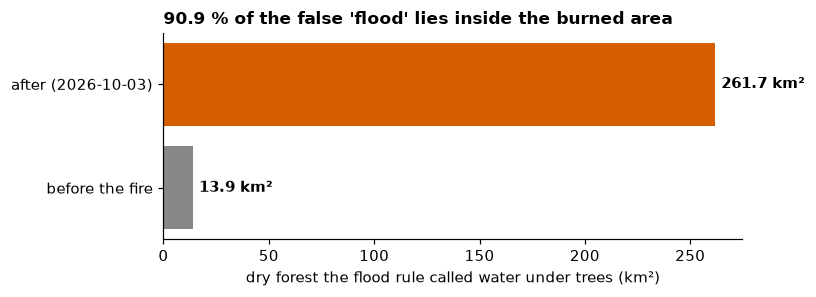

In [21]:
fire_file = DATA / "thunder_bay_36" / "summary.json"
if fire_file.exists():
    look = json.loads(fire_file.read_text())["products"]["burn"]["flood_lookalike"]
    fig, ax = plt.subplots(figsize=(7.5, 2.8))
    ax.barh(["before the fire", f"after ({look['date']})"], [look["before_km2"], look["km2"]], color=["#888", C["burn"]])
    for y_, v in enumerate([look["before_km2"], look["km2"]]):
        ax.text(v + 3, y_, f"{v:.1f} km²", va="center", weight="bold")
    ax.set_xlabel("dry forest the flood rule called water under trees (km²)")
    ax.set_title(f"{look['in_burned_pct']} % of the false 'flood' lies inside the burned area")
    plt.tight_layout(); plt.show()

A radar signature is evidence, not proof: before trusting a flood map, ask what else makes the same signature and check for it (fire records, building footprints, or the time series: a burn stays, a flood comes and goes).

## Taking the map into a GIS

The flood map of the wettest pass as a **GeoTIFF** on the site's own latitude–longitude grid (EPSG:4326), with
the class codes recorded inside the file. Open it in QGIS or ArcGIS.

In [22]:
try:
    import rasterio
    from rasterio.transform import from_bounds
except ImportError:
    print("pip install rasterio to write GeoTIFFs")
else:
    out = Path(f"{SITE}_{passes[i]['id']}_class.tif")
    with rasterio.open(out, "w", driver="GTiff", width=W, height=H, count=1, dtype="uint8", crs="EPSG:4326",
                       transform=from_bounds(west, south, east, north, W, H), nodata=NODATA, compress="deflate") as dst:
        dst.write(cls[i], 1)
        dst.update_tags(classes="0 no data, 1 dry, 2 open water, 3 water under vegetation, 4 built-up (not assessed)",
                        source="Under the Canopy published build; NASA-ISRO NISAR L2 GCOV, provisional", date=passes[i]["date"])
    print("Wrote", out, f"({out.stat().st_size / 1024:.0f} KB)")

Wrote sylhet_p01_class.tif (10 KB)


## What would you study next?

1. **Better labels, better areas.** Design a stratified random sample of reference pixels (Olofsson et al. 2014),
   label them from field knowledge or high-resolution imagery, and estimate the area with a confidence interval.
2. **Thresholds per forest.** Does the best HH threshold depend on canopy height or cover (GEDI)? Fit it, and
   test it at another of the project's 26 sites.
3. **Time, not just space.** A flood comes and goes; a building does not. Use every pass per pixel to separate
   flooding from look-alikes.
4. **Transfer.** Does a threshold or model tuned here hold elsewhere? Use spatial and *site* hold-outs.
5. **Beyond extent.** NISAR's interferograms (GUNW) measure centimetre changes of the water level *under* the trees,
   where the double bounce keeps the signal coherent. Can level and extent give volume?

## Limits

* NISAR's 2026 products are **provisional**; values here are multilooked to about 63 m and stored to 0.25 dB.
* One site, one track, 7 passes, 2 with C-band. Small samples carry wide intervals, and we show them.
* The thresholds were calibrated at this site (D-045).
* C-band water maps and SWOT are other satellites, not ground truth.

## References

1. Hess, L. L., Melack, J. M., and Simonett, D. S. (1990). Radar detection of flooding beneath the forest canopy: a review. *International Journal of Remote Sensing* 11(7), 1313–1325.
2. Hess, L. L., Melack, J. M., Novo, E. M. L. M., Barbosa, C. C. F., and Gastil, M. (2003). Dual-season mapping of wetland inundation and vegetation for the central Amazon basin. *Remote Sensing of Environment* 87, 404–428 (verify pages).
3. Hess, L. L., et al. (2015). Wetlands of the lowland Amazon basin: extent, vegetative cover, and dual-season inundated area as mapped with JERS-1 synthetic aperture radar. *Wetlands* 35, 745–756 (verify pages). Data: ORNL DAAC, doi:10.3334/ORNLDAAC/1284.
4. Rosenqvist, J., Rosenqvist, A., Jensen, K., and McDonald, K. (2020). Mapping of maximum and minimum inundation extents in the Amazon basin 2014–2017 with ALOS-2 PALSAR-2 ScanSAR time-series data. *Remote Sensing* 12(8), 1326.
5. Tsyganskaya, V., Martinis, S., Marzahn, P., and Ludwig, R. (2018). SAR-based detection of flooded vegetation – a review of characteristics and approaches. *International Journal of Remote Sensing* 39(8), 2255–2293.
6. Roberts, D. R., et al. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography* 40(8), 913–929.
7. Bonafilia, D., Tellman, B., Anderson, T., and Issenberg, E. (2020). Sen1Floods11: a georeferenced dataset to train and test deep learning flood algorithms for Sentinel-1. *CVPR Workshops*, 210–211.
8. Pekel, J.-F., Cottam, A., Gorelick, N., and Belward, A. S. (2016). High-resolution mapping of global surface water and its long-term changes. *Nature* 540, 418–422.
9. Nobre, A. D., et al. (2011). Height Above the Nearest Drainage – a hydrologically relevant new terrain model. *Journal of Hydrology* 404, 13–29.
10. Dubayah, R., et al. (2020). The Global Ecosystem Dynamics Investigation: high-resolution laser ranging of the Earth's forests and topography. *Science of Remote Sensing* 1, 100002.
11. Olofsson, P., et al. (2014). Good practices for estimating area and assessing accuracy of land change. *Remote Sensing of Environment* 148, 42–57.
12. Crameri, F., Shephard, G. E., and Heron, P. J. (2020). The misuse of colour in science communication. *Nature Communications* 11, 5444.
13. NASA-ISRO SAR (NISAR) Mission Science Users' Handbook, NASA Jet Propulsion Laboratory ([nisar.jpl.nasa.gov](https://nisar.jpl.nasa.gov)).
14. This project: `docs/03_ARCHITECTURE.md` §4 (the files), `docs/10_DECISIONS_AND_RISKS.md` (why each choice was made).

*Data: NISAR, NASA-ISRO, via the Alaska Satellite Facility DAAC; OPERA DSWx-S1 and RTC-S1, NASA JPL; GPM IMERG and SWOT, NASA (SWOT with CNES); GEDI, NASA; JRC Global Surface Water, European Commission; GLO-30 HAND, ASF; ESA WorldCover; river gauges as named in each site's summary.*